In [1]:
import sys
sys.path.insert(0, "..")
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import zoom

from src import io_utils, fluence_utils, optical_props, correct

cfg = io_utils.load_config("dataset")
opt_cfg = io_utils.load_config("optical_props_750nm")
classes = cfg["classes"]
pixel_mm = cfg["pixel_mm"]
top_mm = cfg["image_top_depth_mm"]

class_maps = np.load(io_utils.project_path("data", "processed", "class_maps.npy"))
dist = np.load(io_utils.project_path("data", "processed", "skin_distance_mm.npy"))
props = optical_props.class_properties(opt_cfg)
n_frames, n_rows, n_cols = class_maps.shape
extent = [0, n_cols * pixel_mm, top_mm + n_rows * pixel_mm, top_mm]
x_mm = np.arange(n_cols) * pixel_mm
z_mm = top_mm + np.arange(n_rows) * pixel_mm
tissue = (class_maps > 0) & (dist > 0)

Loading the MC Maps (already generated in Previously)

In [2]:
mc_small = np.load(io_utils.project_path("data", "mc_v1", "fluence_mc_nominal.npy"))
split = json.load(open(io_utils.project_path("data", "mc_v1", "split.json")))
shot_frames, pool, test_frames = split["shot_frames"], split["pool"], split["test_frames"]
flagged = json.load(open(io_utils.project_path("data", "processed", "crop_info.json")))["breathing_flagged_frames"]
print("Version-1 MC maps:", mc_small.shape, "(2x smaller grid, 0.0704 mm)")
print("Training frames with MC (shots):", shot_frames, " - breathing frames among them:", [f for f in shot_frames if f in flagged])
print(f"Training pool: frames {pool[0]}–{pool[-1]}   Test block: frames {test_frames[0]}–{test_frames[-1]} ({len(test_frames)} frames)")

Version-1 MC maps: (197, 254, 300) (2x smaller grid, 0.0704 mm)
Training frames with MC (shots): [18, 56, 76, 94, 140]  - breathing frames among them: [56, 94, 140]
Training pool: frames 0–155   Test block: frames 156–196 (41 frames)


Downsampled (in version 1), now to Full Resolution

In [3]:
phi_mc = correct.upsample_fluence(mc_small, (n_rows, n_cols))
phi_mc = np.stack([fluence_utils.normalise_fluence(phi_mc[f], dist[f]) for f in range(n_frames)]).astype(np.float32)

back = np.exp(zoom(np.log(phi_mc), (1, mc_small.shape[1] / n_rows, mc_small.shape[2] / n_cols), order=1))
small_tissue = class_maps[:, ::2, ::2][:, :mc_small.shape[1], :mc_small.shape[2]] > 0
ratio = back / mc_small
ratio = ratio / np.median(ratio[small_tissue])
print(f"Round trip (full grid -> small grid) vs version 1, in tissue: median |error| {100 * np.median(np.abs(ratio[small_tissue] - 1)):.2f} %, "
      f"95th percentile {100 * np.percentile(np.abs(ratio[small_tissue] - 1), 95):.2f} %")
band = (dist >= 0.5) & (dist <= 1.0)
band_mean_log = [np.log(phi_mc[f][band[f]]).mean() for f in range(n_frames)]
print(f"Mean log-fluence in the normalisation band: largest |value| over all frames {np.max(np.abs(band_mean_log)):.2e} (must be 0)")

Round trip (full grid -> small grid) vs version 1, in tissue: median |error| 0.63 %, 95th percentile 2.47 %
Mean log-fluence in the normalisation band: largest |value| over all frames 4.44e-08 (must be 0)


The MC fluence maps

Global 0-1 factor: 2.572 (in units of the fluence just under the skin)


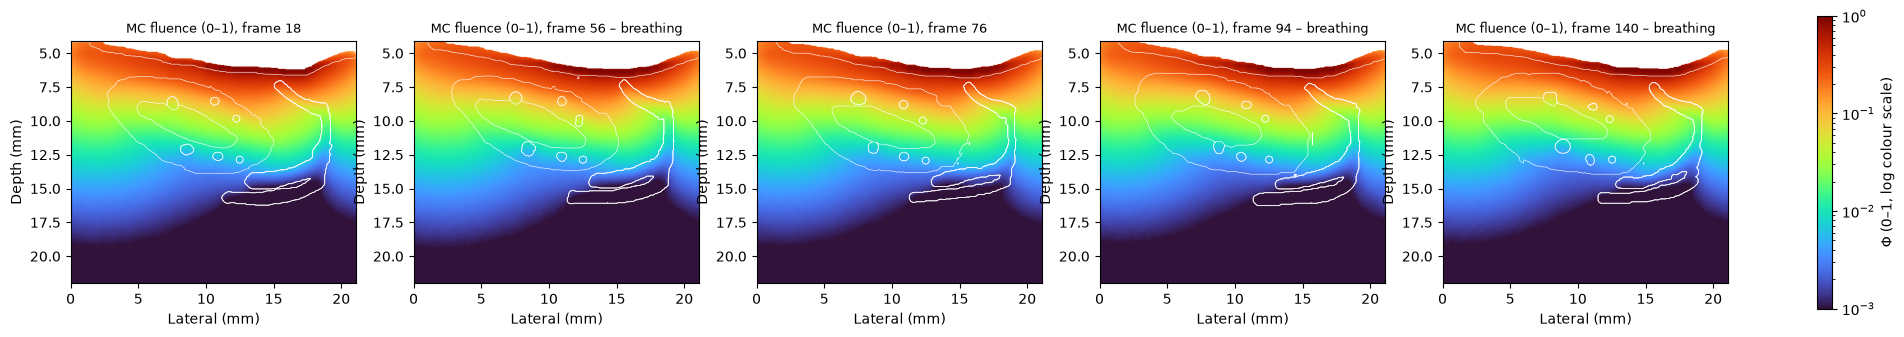

In [4]:
scale_01 = fluence_utils.unit_scale(phi_mc, tissue)
print(f"Global 0-1 factor: {scale_01:.3f} (in units of the fluence just under the skin)")

fig, axes = plt.subplots(1, len(shot_frames), figsize=(4.6 * len(shot_frames), 3.8))
for ax, f in zip(axes, shot_frames):
    im = ax.imshow(np.where(tissue[f], fluence_utils.to_unit_range(phi_mc[f], scale_01), np.nan), cmap="turbo",
                   norm=LogNorm(vmin=1e-3, vmax=1), extent=extent)
    ax.contour(x_mm, z_mm, class_maps[f], levels=[0.5, 1.5, 2.5, 3.5, 4.5], colors="w", linewidths=0.4)
    ax.set_title(f"MC fluence (0–1), frame {f}" + (" – breathing" if f in flagged else ""), fontsize=9)
    ax.set_xlabel("Lateral (mm)")
    ax.set_ylabel("Depth (mm)")
plt.colorbar(im, ax=axes, label="Φ (0–1, log colour scale)", fraction=0.02)
io_utils.save_figure(fig, "04_mc_training_frames")
plt.show()

Fluence vs depth


Apparent attenuation (2–12 mm): 0.554 1/mm (version 1 on the small grid: 0.555 1/mm)
Fluence at 5 mm: 0.060, at 10 mm: 0.0041


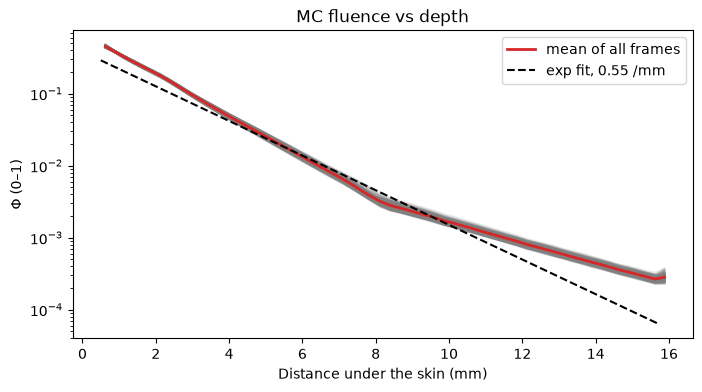

In [5]:
bins = np.arange(0.5, 16, 0.25)
profiles = np.full((n_frames, len(bins)), np.nan)
for f in range(n_frames):
    for i, b in enumerate(bins):
        sel = tissue[f] & (dist[f] >= b) & (dist[f] < b + 0.25)
        if sel.sum() > 80:
            profiles[f, i] = np.median(phi_mc[f][sel])
mean_profile = np.nanmean(profiles, axis=0)
fit = (bins > 2) & (bins < 12) & np.isfinite(mean_profile)
slope, intercept = np.polyfit(bins[fit], np.log(mean_profile[fit]), 1)
print(f"Apparent attenuation (2–12 mm): {-slope:.3f} 1/mm (version 1 on the small grid: 0.555 1/mm)")
print(f"Fluence at 5 mm: {np.interp(5, bins, mean_profile):.3f}, at 10 mm: {np.interp(10, bins, mean_profile):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
for p in profiles:
    ax.semilogy(bins + 0.125, p / scale_01, color="grey", alpha=0.15)
ax.semilogy(bins + 0.125, mean_profile / scale_01, color="tab:red", lw=2, label="mean of all frames")
ax.semilogy(bins, np.exp(intercept + slope * bins) / scale_01, "k--", label=f"exp fit, {-slope:.2f} /mm")
ax.set_xlabel("Distance under the skin (mm)")
ax.set_ylabel("Φ (0–1)")
ax.set_title("MC fluence vs depth")
ax.legend()
io_utils.save_figure(fig, "04_mc_depth_profile")
plt.show()

Validation of the MC set-up (version 1)

In [6]:
v1 = io_utils.project_path("v1_reference", "tables", "x").parent
for name, title in [("04_mc_validation_slabs.csv", "Slabs vs adding-doubling (Prahl)"),
                    ("04_mc_validation_diffusion.csv", "Broad beam vs diffusion theory"),
                    ("04_mc_domain_convergence.csv", "Size of the simulated volume"),
                    ("04_mc_sensitivity.csv", "Sensitivity of the kidney fluence to the optical properties")]:
    print(f"\n{title}:")
    print(pd.read_csv(v1 / name).round(4).to_string(index=False))


Slabs vs adding-doubling (Prahl):
                                 slab  R MCX  R adding-doubling  T MCX  T adding-doubling  R error %  T error %
classic (albedo 0.9, τ = 2, g = 0.75) 0.0973             0.0974 0.6611             0.6626    -0.0981    -0.2293
                       our skin, 1 mm 0.4892             0.4893 0.4891             0.4892    -0.0220    -0.0171
                     our cortex, 1 mm 0.4336             0.4338 0.4425             0.4425    -0.0435     0.0011

Broad beam vs diffusion theory:
     tissue  mu_eff MC (1/mm)  mu_eff diffusion theory (1/mm)  difference %
soft_tissue            0.2573                          0.2533        1.5791
     cortex            0.6061                          0.6115       -0.8803

Size of the simulated volume:
 elevation size (mm)  effective decay 2–12 mm (1/mm)  fluence at 10 mm
                  10                          0.5869            0.0033
                  20                          0.5607            0.0040
            

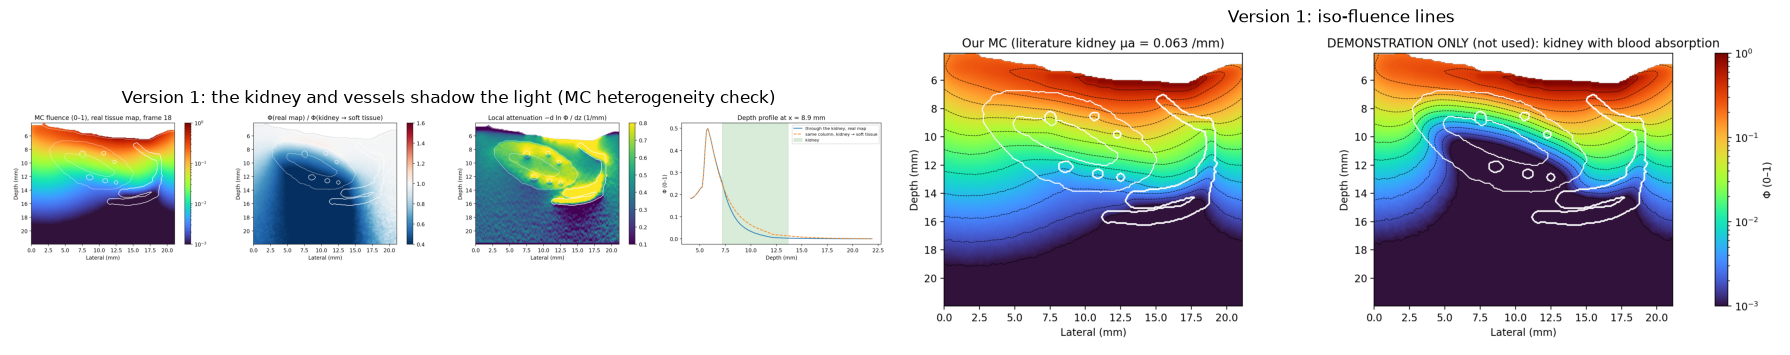

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, name in zip(axes, ["04_mc_heterogeneity_check.png", "04_mc_isofluence_blood_kidney.png"]):
    ax.imshow(plt.imread(io_utils.project_path("v1_reference", "figures", name)))
    ax.axis("off")
axes[0].set_title("Version 1: the kidney and vessels shadow the light (MC heterogeneity check)")
axes[1].set_title("Version 1: iso-fluence lines")
plt.tight_layout()
plt.show()

## 7. Save

In [8]:
out = io_utils.project_path("data", "mc", "x").parent
np.save(out / "fluence_mc.npy", phi_mc)
with open(out / "split.json", "w") as fh:
    json.dump({"shot_frames": shot_frames, "pool": pool, "test_frames": test_frames, "scale_01": scale_01}, fh)
print("Saved", phi_mc.shape, "to", out)

Saved (197, 509, 600) to /home/vishal/Vishal/CAPSTONE/FLUENCE_PINN_MAIN_V2/data/mc
